<a href="https://colab.research.google.com/github/maureljean55/atelier-saint-honore/blob/main/notebooks/q8_ca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

clients = pd.read_csv("sample_data/client_propre.csv")

cols = ["anciennete_mois", "nb_achats_12m", "panier_moyen_eur"]
X = StandardScaler().fit_transform(clients[cols])
clients["cluster"] = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X)

noms = {
    0: "Gros acheteurs VIP",
    1: "Occasionnels récents",
    2: "Fidèles historiques"
}
clients["profil"] = clients["cluster"].map(noms)

clients["profil"].value_counts()

,count
profil,
Occasionnels récents,367
Fidèles historiques,219
Gros acheteurs VIP,93


In [2]:
ca_total = clients["montant_total_eur"].sum()

ca_profil = clients.groupby("profil").agg(
    nb_clients=("client_id", "count"),
    ca_moyen_client=("montant_total_eur", "mean"),
    ca_total_12m=("montant_total_eur", "sum")
)

ca_profil["part_clients_pct"] = ca_profil["nb_clients"] / len(clients) * 100
ca_profil["part_ca_pct"] = ca_profil["ca_total_12m"] / ca_total * 100

ca_profil = ca_profil[["nb_clients", "part_clients_pct", "ca_moyen_client", "ca_total_12m", "part_ca_pct"]]
ca_profil.round(1).sort_values("ca_total_12m", ascending=False)

,nb_clients,part_clients_pct,ca_moyen_client,ca_total_12m,part_ca_pct
profil,,,,,
Gros acheteurs VIP,93,13.7,58543.3,5444523.0,63.4
Occasionnels récents,367,54.1,4865.1,1785509.0,20.8
Fidèles historiques,219,32.3,6202.3,1358299.0,15.8


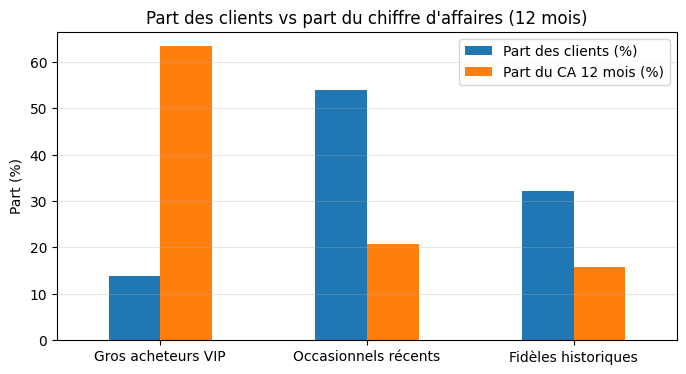

In [3]:
donnees_graph = ca_profil[["part_clients_pct", "part_ca_pct"]].sort_values("part_ca_pct", ascending=False)

donnees_graph.plot(kind="bar", figsize=(8, 4))
plt.ylabel("Part (%)")
plt.xlabel("")
plt.title("Part des clients vs part du chiffre d'affaires (12 mois)")
plt.xticks(rotation=0)
plt.legend(["Part des clients (%)", "Part du CA 12 mois (%)"])
plt.grid(axis="y", alpha=0.3)
plt.show()

In [4]:
clients["evolution_panier_pct"] = (clients["montant_prochain_achat_eur"] / clients["panier_moyen_eur"] - 1) * 100
ca_prochain_total = clients["montant_prochain_achat_eur"].sum()

prochain = clients.groupby("profil").agg(
    panier_moyen=("panier_moyen_eur", "mean"),
    prochain_achat_moy=("montant_prochain_achat_eur", "mean"),
    evol_panier_med_pct=("evolution_panier_pct", "median"),
    ca_prochain_total=("montant_prochain_achat_eur", "sum")
)

prochain["part_ca_prochain_pct"] = prochain["ca_prochain_total"] / ca_prochain_total * 100
prochain.round(1).sort_values("ca_prochain_total", ascending=False)

,panier_moyen,prochain_achat_moy,evol_panier_med_pct,ca_prochain_total,part_ca_prochain_pct
profil,,,,,
Occasionnels récents,2221.0,1717.3,-22.0,630233.0,47.0
Gros acheteurs VIP,6406.7,4051.6,-35.9,376795.0,28.1
Fidèles historiques,1752.0,1527.6,-16.6,334545.0,24.9


In [5]:
clients["ca_a_risque"] = clients["montant_total_eur"].where(clients["est_revenu_6m"] == 0, 0)

risque = clients.groupby("profil").agg(
    nb_clients=("client_id", "count"),
    nb_partis=("est_revenu_6m", lambda s: (s == 0).sum()),
    taux_depart_pct=("est_revenu_6m", lambda s: (1 - s.mean()) * 100),
    ca_total_12m=("montant_total_eur", "sum"),
    ca_a_risque_12m=("ca_a_risque", "sum")
)

risque["part_ca_a_risque_pct"] = risque["ca_a_risque_12m"] / risque["ca_total_12m"] * 100
risque.round(1).sort_values("ca_a_risque_12m", ascending=False)

,nb_clients,nb_partis,taux_depart_pct,ca_total_12m,ca_a_risque_12m,part_ca_a_risque_pct
profil,,,,,,
Gros acheteurs VIP,93,36,38.7,5444523.0,2049733.0,37.6
Occasionnels récents,367,250,68.1,1785509.0,1170423.0,65.6
Fidèles historiques,219,115,52.5,1358299.0,665300.0,49.0


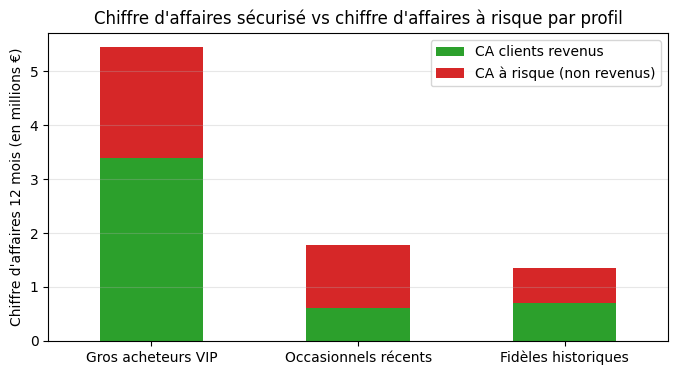

In [6]:
ca_empile = pd.DataFrame({
    "CA clients revenus": risque["ca_total_12m"] - risque["ca_a_risque_12m"],
    "CA à risque (non revenus)": risque["ca_a_risque_12m"]
}).sort_values("CA à risque (non revenus)", ascending=False)

(ca_empile / 1e6).plot(kind="bar", stacked=True, figsize=(8, 4), color=["#2ca02c", "#d62728"])
plt.ylabel("Chiffre d'affaires 12 mois (en millions €)")
plt.xlabel("")
plt.title("Chiffre d'affaires sécurisé vs chiffre d'affaires à risque par profil")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

In [7]:
clients.groupby("profil").agg(
    anciennete_mois=("anciennete_mois", "mean"),
    nb_achats_12m=("nb_achats_12m", "mean"),
    panier_moyen=("panier_moyen_eur", "mean"),
    retours_moy=("retours", "mean"),
    sav_moy=("demandes_sav", "mean"),
    taux_retour_pct=("est_revenu_6m", lambda s: s.mean() * 100)
).round(1)

,anciennete_mois,nb_achats_12m,panier_moyen,retours_moy,sav_moy,taux_retour_pct
profil,,,,,,
Fidèles historiques,61.4,3.5,1752.0,0.3,0.4,47.5
Gros acheteurs VIP,15.0,9.4,6406.7,1.3,0.3,61.3
Occasionnels récents,16.7,2.3,2221.0,0.4,0.4,31.9


In [8]:
(pd.crosstab(clients["profil"], clients["canal_prefere"], normalize="index") * 100).round(1)

canal_prefere,boutique,en ligne,mixte
profil,,,
Fidèles historiques,53.4,23.3,23.3
Gros acheteurs VIP,54.8,26.9,18.3
Occasionnels récents,60.5,21.3,18.3


In [9]:
(pd.crosstab(clients["profil"], clients["carte_fidelite"], normalize="index") * 100).round(1)

carte_fidelite,argent,aucune,or
profil,,,
Fidèles historiques,35.6,51.1,13.2
Gros acheteurs VIP,32.3,49.5,18.3
Occasionnels récents,36.5,48.5,15.0


In [10]:
traitements = {
    "Gros acheteurs VIP": "Avant-première + suivi dédié (vérifier les gros retours en Q9)",
    "Fidèles historiques": "Invitation collection (ou rien pour les plus réguliers)",
    "Occasionnels récents": "Relance ciblée (seuil Q6) ; rien pour les autres"
}

feuille_route = ca_profil[["nb_clients", "part_clients_pct", "ca_total_12m", "part_ca_pct"]].copy()
feuille_route["taux_depart_pct"] = risque["taux_depart_pct"]
feuille_route["ca_a_risque_12m"] = risque["ca_a_risque_12m"]
feuille_route["traitement"] = feuille_route.index.map(traitements)

feuille_route.round(1).sort_values("ca_total_12m", ascending=False)

,nb_clients,part_clients_pct,ca_total_12m,part_ca_pct,taux_depart_pct,ca_a_risque_12m,traitement
profil,,,,,,,
Gros acheteurs VIP,93,13.7,5444523.0,63.4,38.7,2049733.0,Avant-première + suivi dédié (vérifier les gro...
Occasionnels récents,367,54.1,1785509.0,20.8,68.1,1170423.0,Relance ciblée (seuil Q6) ; rien pour les autres
Fidèles historiques,219,32.3,1358299.0,15.8,52.5,665300.0,Invitation collection (ou rien pour les plus r...
